# Demo 1: Function approximation with a neural network

A short, hands-on study of a neural network as an **approximation tool** — the role it plays in scientific computing. We answer the questions a numerical analyst would ask first:

1. How does accuracy depend on width and depth? *(capacity)*
2. ReLU or tanh — and what do the network's **derivatives** look like? *(smoothness)*
3. How does it compare with polynomial interpolation on the Runge function? *(a familiar benchmark)*
4. What happens **outside** the training interval? *(extrapolation)*
5. Which features of a function are learned first? *(spectral bias — optional)*
6. Scattered data in two dimensions. *(no grid needed)*

Everything uses the ~15-line PyTorch training loop from Session 2, wrapped in two helper functions.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import time

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 100, "font.size": 11})
torch.set_default_dtype(torch.float64)        # double precision: we will look at small errors

In [ ]:
def make_mlp(width=32, depth=2, act=nn.Tanh, d_in=1, d_out=1):
    '''Fully-connected network: d_in -> width -> ... -> width -> d_out, `depth` hidden layers.'''
    layers, d = [], d_in
    for _ in range(depth):
        layers += [nn.Linear(d, width), act()]; d = width
    layers.append(nn.Linear(d, d_out))
    return nn.Sequential(*layers)

def train(model, x, y, epochs=3000, lr=1e-2, lbfgs_steps=0, snapshots=(), x_eval=None, verbose=False):
    '''Full-batch Adam on the mean-squared error, optionally polished with L-BFGS.
    Returns the loss history and optional snapshots of the fit.'''
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)   # slowly decrease the step size
    losses, snaps = [], {}
    t0 = time.perf_counter()
    for ep in range(epochs):
        opt.zero_grad()
        loss = ((model(x) - y) ** 2).mean()
        loss.backward(); opt.step(); sched.step()
        losses.append(loss.item())
        if ep in snapshots:
            with torch.no_grad(): snaps[ep] = model(x_eval).numpy().copy()
    if lbfgs_steps:                       # quasi-Newton polish: standard for small full-batch problems
        opt2 = torch.optim.LBFGS(model.parameters(), max_iter=lbfgs_steps, history_size=50,
                                 line_search_fn="strong_wolfe", tolerance_grad=1e-12, tolerance_change=1e-14)
        def closure():
            opt2.zero_grad(); l = ((model(x) - y) ** 2).mean(); l.backward(); losses.append(l.item()); return l
        opt2.step(closure)
    if verbose: print(f"  {epochs} Adam epochs" + (f" + {lbfgs_steps} L-BFGS steps" if lbfgs_steps else "")
                      + f", {time.perf_counter()-t0:.1f} s, final MSE {losses[-1]:.2e}")
    return losses, snaps

def rmse(model, x, f):
    '''Root-mean-square error of the network against a target function f on points x.'''
    with torch.no_grad(): return ((model(x) - f(x)) ** 2).mean().sqrt().item()

col = lambda a: torch.tensor(np.asarray(a).reshape(-1, 1))     # numpy -> column tensor

## 1. Warm-up: fit $\sin(x)$

200 noisy samples on $[-\pi,\pi]$, a 1→32→32→1 tanh network, 3 000 Adam steps.

  3000 Adam epochs, 3.1 s, final MSE 2.25e-03
  RMSE against the exact sin on a fine grid: 1.49e-02   (noise level in the data: 5e-2)


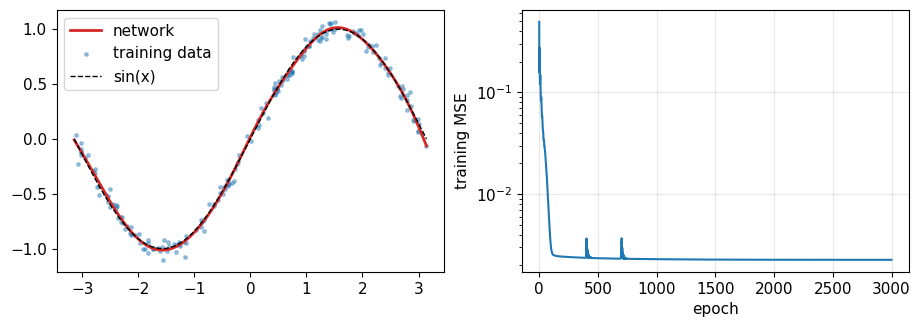

In [ ]:
f = torch.sin
x_tr = col(np.random.uniform(-np.pi, np.pi, 200)); y_tr = f(x_tr) + 0.05 * torch.randn_like(x_tr)
x_fine = col(np.linspace(-np.pi, np.pi, 500))

net = make_mlp(32, 2)
losses, _ = train(net, x_tr, y_tr, epochs=3000, verbose=True)
print(f"  RMSE against the exact sin on a fine grid: {rmse(net, x_fine, f):.2e}   (noise level in the data: 5e-2)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
with torch.no_grad(): ax[0].plot(x_fine, net(x_fine), "C3", lw=2, label="network")
ax[0].scatter(x_tr, y_tr, s=6, alpha=0.4, label="training data"); ax[0].plot(x_fine, f(x_fine), "k--", lw=1, label="sin(x)")
ax[0].legend(); ax[1].semilogy(losses); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training MSE"); ax[1].grid(alpha=0.3)
plt.show()

Note the network's error is *below* the noise level: with 200 points and a smooth target, the network averages the noise out rather than fitting it. (More epochs, fewer points, or a much larger network would eventually overfit, as in Session 2.)

## 2. Capacity: width and depth

Fix the data and the training budget; vary the architecture. The target now has a sharper feature to make the task harder:
$\;g(x) = \sin(2x) + \tanh(8x)/2$ on $[-\pi,\pi]$.

--- width (one hidden layer) ---


  width   4:    13 parameters, RMSE 1.89e-01


  width  16:    49 parameters, RMSE 3.94e-02


  width  64:   193 parameters, RMSE 3.98e-02


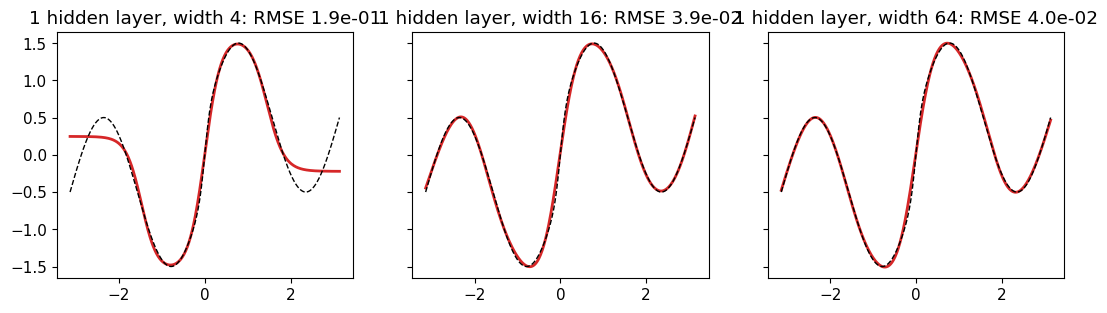

--- depth (width 16) ---


  depth 1:    49 parameters, RMSE 3.94e-02


  depth 2:   321 parameters, RMSE 6.98e-03


  depth 4:   865 parameters, RMSE 3.26e-03


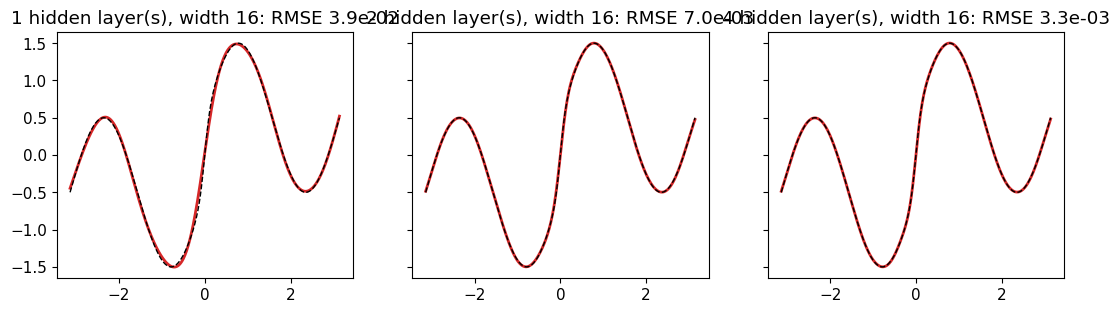

In [ ]:
g = lambda x: torch.sin(2 * x) + 0.5 * torch.tanh(8 * x)
y_g = g(x_tr)

print("--- width (one hidden layer) ---")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, width in zip(axes, [4, 16, 64]):
    torch.manual_seed(0); net = make_mlp(width, 1); train(net, x_tr, y_g, 3000)
    e = rmse(net, x_fine, g); print(f"  width {width:3d}: {sum(p.numel() for p in net.parameters()):5d} parameters, RMSE {e:.2e}")
    with torch.no_grad(): ax.plot(x_fine, net(x_fine), "C3", lw=2)
    ax.plot(x_fine, g(x_fine), "k--", lw=1); ax.set_title(f"1 hidden layer, width {width}: RMSE {e:.1e}")
plt.show()

print("--- depth (width 16) ---")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, depth in zip(axes, [1, 2, 4]):
    torch.manual_seed(0); net = make_mlp(16, depth); train(net, x_tr, y_g, 3000)
    e = rmse(net, x_fine, g); print(f"  depth {depth}: {sum(p.numel() for p in net.parameters()):5d} parameters, RMSE {e:.2e}")
    with torch.no_grad(): ax.plot(x_fine, net(x_fine), "C3", lw=2)
    ax.plot(x_fine, g(x_fine), "k--", lw=1); ax.set_title(f"{depth} hidden layer(s), width 16: RMSE {e:.1e}")
plt.show()

Two typical observations: (i) accuracy improves with capacity but **saturates** — width 16 and width 64 give the same error; (ii) for a fixed budget, **depth buys more than width**. There is no $h$-refinement theory here: accuracy vs. size is purely empirical.

**Is the plateau the architecture or the optimiser?** Test it: take the width-16 network that stalled and polish it with L-BFGS, a quasi-Newton method that uses curvature information (and that we will use again for the PINN).

In [ ]:
torch.manual_seed(0); net = make_mlp(16, 1)
train(net, x_tr, y_g, 3000);                     e_adam = rmse(net, x_fine, g)
train(net, x_tr, y_g, epochs=0, lbfgs_steps=500); e_lbfgs = rmse(net, x_fine, g)
print(f"width 16, one hidden layer:   Adam only  RMSE {e_adam:.2e}   ->   after L-BFGS polish  RMSE {e_lbfgs:.2e}")

width 16, one hidden layer:   Adam only  RMSE 3.94e-02   ->   after L-BFGS polish  RMSE 2.34e-03


Same 49 parameters, an order of magnitude better: the plateau was the **optimiser**, not the expressive power. This is the general situation with networks — the architecture is rarely the bottleneck, training is — and it is why $10^{-3}$–$10^{-4}$ relative error is the typical ceiling for a small network in practice, however many parameters you add. Keep that number in mind for the Burgers demo.

## 3. ReLU vs tanh — and the network's derivatives

For scientific computing we often need **derivatives** of the approximant (fluxes, residuals, PDE operators). Automatic differentiation gives $u_\theta'(x)$ exactly. But what it gives depends on the activation: a ReLU network is piecewise linear, so $u_\theta'$ is a **step function** and $u_\theta''\equiv 0$. A tanh network is $C^\infty$.

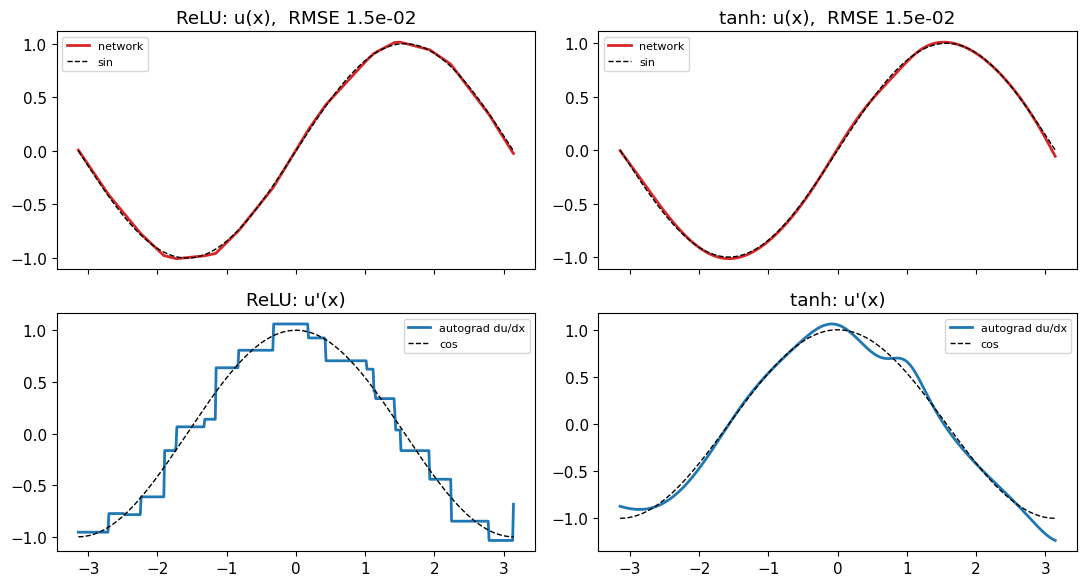

In [ ]:
def derivative(model, x):
    '''du/dx by automatic differentiation.'''
    x = x.clone().requires_grad_(True)
    u = model(x)
    return torch.autograd.grad(u.sum(), x)[0].detach()

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for j, (act, name) in enumerate([(nn.ReLU, "ReLU"), (nn.Tanh, "tanh")]):
    torch.manual_seed(0); net = make_mlp(32, 2, act); train(net, x_tr, y_tr, 3000)
    with torch.no_grad(): axes[0, j].plot(x_fine, net(x_fine), "C3", lw=2, label="network")
    axes[0, j].plot(x_fine, torch.sin(x_fine), "k--", lw=1, label="sin"); axes[0, j].set_title(f"{name}: u(x),  RMSE {rmse(net, x_fine, f):.1e}")
    axes[1, j].plot(x_fine, derivative(net, x_fine), "C0", lw=2, label="autograd du/dx")
    axes[1, j].plot(x_fine, torch.cos(x_fine), "k--", lw=1, label="cos"); axes[1, j].set_title(f"{name}: u'(x)")
    axes[0, j].legend(fontsize=8); axes[1, j].legend(fontsize=8)
plt.tight_layout(); plt.show()

Both fit $u$ comparably, but the ReLU derivative is a staircase. **Rule of thumb:** for data fitting and classification use ReLU; whenever you will differentiate the network (PINNs, surrogates of smooth physics) use tanh or another smooth activation.

## 4. A familiar benchmark: the Runge function

$r(x) = 1/(1+25x^2)$ sampled at **17 equispaced points** on $[-1,1]$. Polynomial interpolation through equispaced nodes famously oscillates (Runge's phenomenon). What does a network trained on the *same 17 points* do?

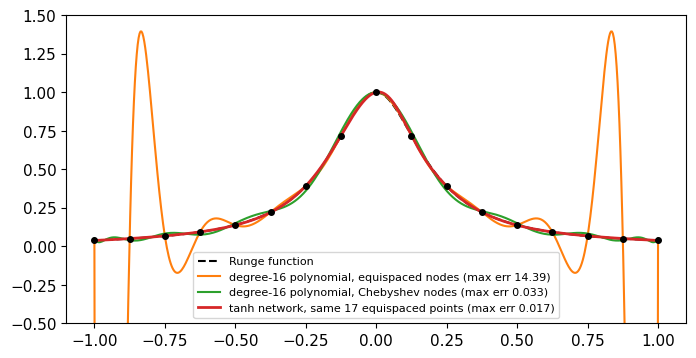

In [ ]:
from scipy.interpolate import BarycentricInterpolator

runge = lambda x: 1 / (1 + 25 * x ** 2)
nodes = np.linspace(-1, 1, 17); xr = np.linspace(-1, 1, 600)
poly_equi = BarycentricInterpolator(nodes, runge(nodes))(xr)
cheb = np.cos(np.pi * (2 * np.arange(17) + 1) / 34)                       # Chebyshev nodes
poly_cheb = BarycentricInterpolator(cheb, runge(cheb))(xr)

torch.manual_seed(0); net = make_mlp(32, 2); train(net, col(nodes), col(runge(nodes)), 4000, lr=3e-3)
with torch.no_grad(): nn_fit = net(col(xr)).numpy().ravel()

plt.figure(figsize=(8, 4))
plt.plot(xr, runge(xr), "k--", lw=1.5, label="Runge function")
plt.plot(xr, poly_equi, "C1", lw=1.5, label=f"degree-16 polynomial, equispaced nodes (max err {np.abs(poly_equi-runge(xr)).max():.2f})")
plt.plot(xr, poly_cheb, "C2", lw=1.5, label=f"degree-16 polynomial, Chebyshev nodes (max err {np.abs(poly_cheb-runge(xr)).max():.3f})")
plt.plot(xr, nn_fit, "C3", lw=2, label=f"tanh network, same 17 equispaced points (max err {np.abs(nn_fit-runge(xr)).max():.3f})")
plt.plot(nodes, runge(nodes), "ko", ms=4); plt.ylim(-0.5, 1.5); plt.legend(fontsize=8); plt.show()

The network produces a smooth, non-oscillating fit from equispaced data. **This is not "networks beat polynomials"** — Chebyshev nodes fix the polynomial completely and converge exponentially, which a network will never do. The point is different: a fixed-degree polynomial is a *linear* approximation in a rigid basis, while the network's basis functions (the $\tanh(w x+b)$ bumps) are themselves adapted to the data. That adaptivity is forgiving of bad sampling, and it is the real reason networks are useful when the sampling is not under your control.

## 5. Extrapolation: the network knows nothing outside the data

Train on $[-\pi,\pi]$, evaluate on $[-3\pi,3\pi]$.

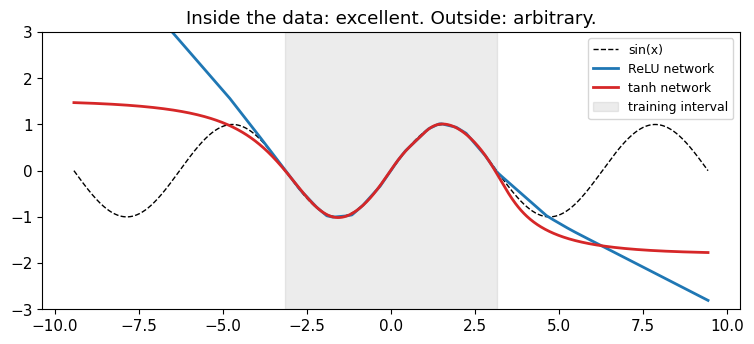

In [ ]:
x_wide = col(np.linspace(-3 * np.pi, 3 * np.pi, 900))
plt.figure(figsize=(9, 3.6))
plt.plot(x_wide, torch.sin(x_wide), "k--", lw=1, label="sin(x)")
for act, name, c in [(nn.ReLU, "ReLU network", "C0"), (nn.Tanh, "tanh network", "C3")]:
    torch.manual_seed(0); net = make_mlp(32, 2, act); train(net, x_tr, y_tr, 3000)
    with torch.no_grad(): plt.plot(x_wide, net(x_wide), c, lw=2, label=name)
plt.axvspan(-np.pi, np.pi, color="gray", alpha=0.15, label="training interval")
plt.ylim(-3, 3); plt.legend(fontsize=9); plt.title("Inside the data: excellent. Outside: arbitrary."); plt.show()

ReLU networks extrapolate **linearly**, tanh networks extrapolate to a **constant** — in both cases the behaviour is determined by the architecture, not by the data, and there is no warning. A neural network is an interpolator. Any use case that requires prediction outside the convex hull of the training data needs either physics built into the loss (PINNs) or a great deal of caution.

## 6. Spectral bias: smooth features are learned first

Target: $s(x) = \sin(\pi x) + \tfrac12\sin(8\pi x)$ on $[-1,1]$. We record snapshots during training and also track the error in each of the two Fourier components separately.

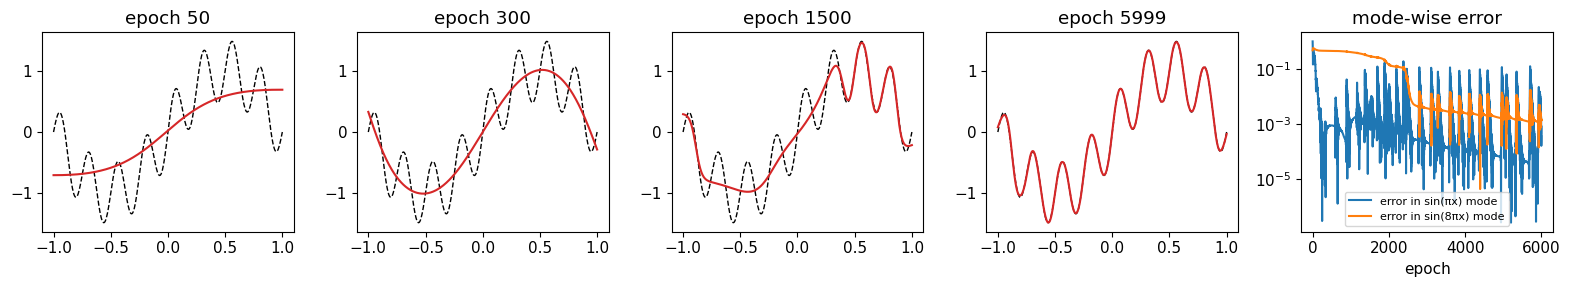

In [ ]:
s = lambda x: torch.sin(np.pi * x) + 0.5 * torch.sin(8 * np.pi * x)
xs_ = col(np.linspace(-1, 1, 400)); ys_ = s(xs_)
snaps_at = (50, 300, 1500, 5999)

torch.manual_seed(0); net = make_mlp(64, 3)
opt = torch.optim.Adam(net.parameters(), lr=2e-3)
low, high, snaps = [], [], {}
phi1, phi8 = torch.sin(np.pi * xs_), torch.sin(8 * np.pi * xs_)
for ep in range(6000):
    opt.zero_grad(); r = net(xs_) - ys_; loss = (r ** 2).mean(); loss.backward(); opt.step()
    with torch.no_grad():                                   # project the residual on the two modes
        low.append(abs((r * phi1).mean().item()) / 0.5); high.append(abs((r * phi8).mean().item()) / 0.5)
        if ep in snaps_at: snaps[ep] = net(xs_).numpy().copy()

fig, axes = plt.subplots(1, len(snaps_at) + 1, figsize=(16, 3))
for ax, ep in zip(axes, snaps_at):
    ax.plot(xs_, ys_, "k--", lw=1); ax.plot(xs_, snaps[ep], "C3", lw=1.5); ax.set_title(f"epoch {ep}")
axes[-1].semilogy(low, label="error in sin(πx) mode"); axes[-1].semilogy(high, label="error in sin(8πx) mode")
axes[-1].legend(fontsize=8); axes[-1].set_xlabel("epoch"); axes[-1].set_title("mode-wise error")
plt.tight_layout(); plt.show()

The low-frequency component is captured within a few hundred epochs; the high-frequency component takes ten times longer. This **spectral bias** is a generic property of gradient-trained networks. It is helpful (it is why networks ignore noise) and harmful (sharp fronts and boundary layers are the last thing a network learns — the Burgers demo will show this).

## 7. Two dimensions, scattered data

Nothing in the code depended on the input being one-dimensional. Here a 2→32→32→32→1 network is trained on 1 500 **randomly scattered** samples of
$\;F(x,y) = \sin(\pi x)\sin(\pi y) + \tfrac12 e^{-20[(x-0.5)^2+(y-0.5)^2]}$ on $[-1,1]^2$. No mesh, no grid — the same code works in 10 dimensions.

  3000 Adam epochs + 500 L-BFGS steps, 11.5 s, final MSE 1.05e-05
  relative L2 error on a 101×101 grid: 7.91e-03


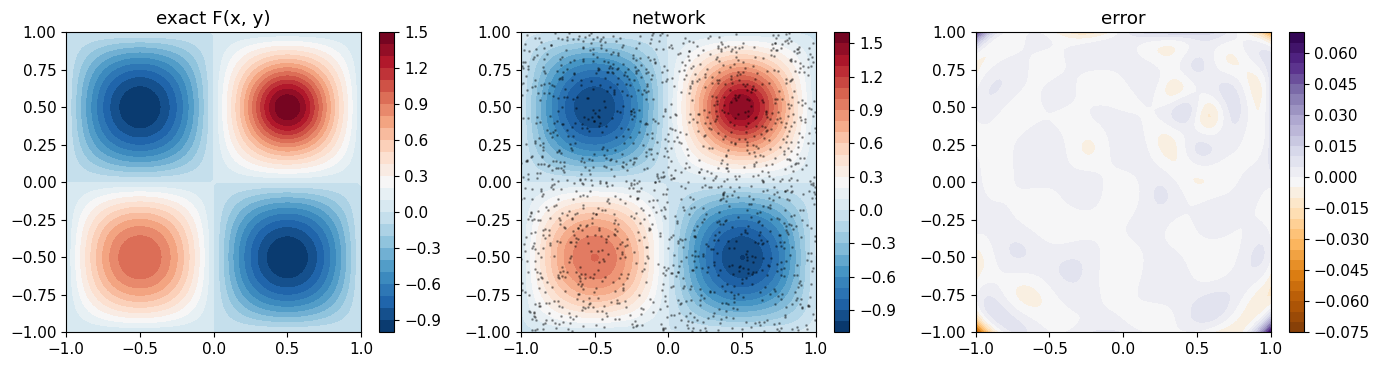

In [ ]:
F = lambda p: torch.sin(np.pi * p[:, :1]) * torch.sin(np.pi * p[:, 1:]) + 0.5 * torch.exp(-20 * ((p[:, :1] - 0.5) ** 2 + (p[:, 1:] - 0.5) ** 2))
p_tr = torch.rand(1500, 2) * 2 - 1
torch.manual_seed(0); net2 = make_mlp(32, 3, d_in=2); train(net2, p_tr, F(p_tr), 3000, lr=3e-3, lbfgs_steps=500, verbose=True)

gx, gy = np.meshgrid(np.linspace(-1, 1, 101), np.linspace(-1, 1, 101))
P = torch.tensor(np.c_[gx.ravel(), gy.ravel()])
with torch.no_grad(): U_nn = net2(P).numpy().reshape(gx.shape)
U_true = F(P).numpy().reshape(gx.shape)
print(f"  relative L2 error on a 101×101 grid: {np.linalg.norm(U_nn - U_true) / np.linalg.norm(U_true):.2e}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, Z, t in zip(axes, [U_true, U_nn, U_nn - U_true], ["exact F(x, y)", "network", "error"]):
    im = ax.contourf(gx, gy, Z, 30, cmap="RdBu_r" if t != "error" else "PuOr"); plt.colorbar(im, ax=ax); ax.set_title(t)
axes[1].scatter(p_tr[:, 0], p_tr[:, 1], s=1, c="k", alpha=0.3)
plt.tight_layout(); plt.show()

## Takeaways

* A small network reaches **$10^{-3}$–$10^{-4}$ relative accuracy** on smooth 1-D functions, roughly $10^{-2}$–$10^{-3}$ in 2-D with a few thousand scattered samples. Classical methods reach machine precision on the same problems; the network's selling points are elsewhere.
* Use **tanh** (or another smooth activation) whenever the network will be differentiated.
* The approximant is **adaptive** (its "basis" moves with the data), **mesh-free**, and works unchanged in any dimension.
* It is an **interpolator**: extrapolation is arbitrary, and sharp features are learned last.

Next: use exactly this machinery as a PDE solver, and compare with finite differences and finite elements.